# A supie flow, step by step

A `Flow` chains Python steps inside an edge function. A step runs as soon as the steps it depends on are done, so independent steps run in parallel. Every finished step is saved, so a run can resume where it stopped, and the saved steps double as an audit trail.

This notebook builds a small credit-scoring flow, draws it, runs it twice and shows what each run saved. It runs under plain CPython with supie's in-memory store, so it needs no Supabase project.

In [1]:
import time
from typing import Any

from IPython.display import Markdown

from diagrams import Attempt, dag, style, timeline
from supie import sleep
from supie.app import set_host
from supie.flow import Flow, MemoryStore
from supie.testing import DEFAULT_ENV, FakeHost

style()
set_host(FakeHost(dict(DEFAULT_ENV)))  # stands in for the edge function's runtime

## The flow

Two checks run first and in parallel: a credit bureau lookup and a fraud check. Here they sleep to stand in for calls to other services. `score` waits for both, `decide` picks a route, and the `when=` conditions run only the step for that route. These are pgflow's conditions, so the same flow can also run durably on pgflow.

`traced` records when each attempt of a step starts and ends, for the timeline further down. supie itself saves each step's outcome without a timestamp.

In [2]:
attempts: list[Attempt] = []
started = [0.0]


def traced(fn: Any) -> Any:
    """Record each attempt of a step: its start, end and whether it raised."""

    async def step(ctx: Any, *args: Any) -> Any:
        start = time.perf_counter() - started[0]
        try:
            result = await fn(ctx, *args)
        except Exception:
            attempts.append(
                Attempt(
                    ctx.step,
                    ctx.attempt,
                    start,
                    time.perf_counter() - started[0],
                    False,
                )
            )
            raise
        attempts.append(
            Attempt(
                ctx.step, ctx.attempt, start, time.perf_counter() - started[0], True
            )
        )
        return result

    step.__name__ = fn.__name__
    return step

In [3]:
store = MemoryStore()
scoring = Flow("scoring", store)


@scoring.step(retries=1, backoff=0.15)
@traced
async def bureau(ctx: Any, application: dict[str, Any]) -> dict[str, Any]:
    await sleep(0.30)
    if application.get("flaky_bureau") and ctx.attempt == 1:
        raise TimeoutError("bureau didn't answer")
    return {"score": application["bureau_score"]}


@scoring.step()
@traced
async def fraud(ctx: Any, application: dict[str, Any]) -> dict[str, Any]:
    await sleep(0.18)
    return {"flag": application["device_risk"] > 0.8}


@scoring.step(depends_on=[bureau, fraud])
@traced
async def score(
    ctx: Any, application: dict[str, Any], bureau: dict[str, Any], fraud: dict[str, Any]
) -> dict[str, Any]:
    await sleep(0.05)
    pd = round(1 / (1 + 2.718 ** ((bureau["score"] - 600) / 40)), 3)
    return {"pd": pd, "fraud": fraud["flag"]}


@scoring.step(depends_on=[score])
@traced
async def decide(
    ctx: Any, application: dict[str, Any], score: dict[str, Any]
) -> dict[str, str]:
    await sleep(0.02)
    risky = score["fraud"] or score["pd"] > 0.08
    return {"route": "review" if risky else "approve"}


@scoring.step(depends_on=[decide], when={"decide": {"route": "approve"}})
@traced
async def approve(
    ctx: Any, application: dict[str, Any], decide: dict[str, str]
) -> dict[str, str]:
    await sleep(0.02)
    return {"decision": "approve"}


@scoring.step(depends_on=[decide], when={"decide": {"route": "review"}})
@traced
async def review(
    ctx: Any, application: dict[str, Any], decide: dict[str, str]
) -> dict[str, str]:
    await sleep(0.02)
    return {"decision": "refer"}

supie knows the flow's shape from the decorators alone, so we can draw it before running anything. The labels on the last two arrows are the `when=` conditions.

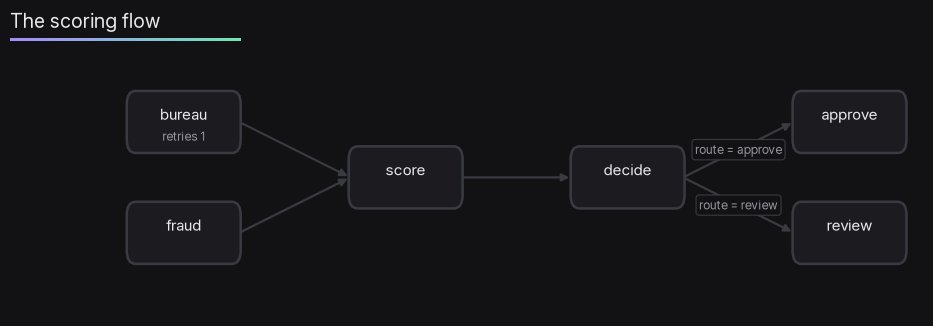

In [4]:
dag(scoring);

## A clean run

A good applicant: a high bureau score and a low device risk. `bureau` and `fraud` start together, `score` starts when the slower one finishes, and only `approve` runs at the end.

In [5]:
order = [s.name for s in scoring.order]


async def run(application: dict[str, Any]) -> Any:
    attempts.clear()
    started[0] = time.perf_counter()
    return await scoring.run(application)


first = await run({"id": 1, "bureau_score": 742, "device_risk": 0.1})
first.output

{'approve': {'decision': 'approve'}}

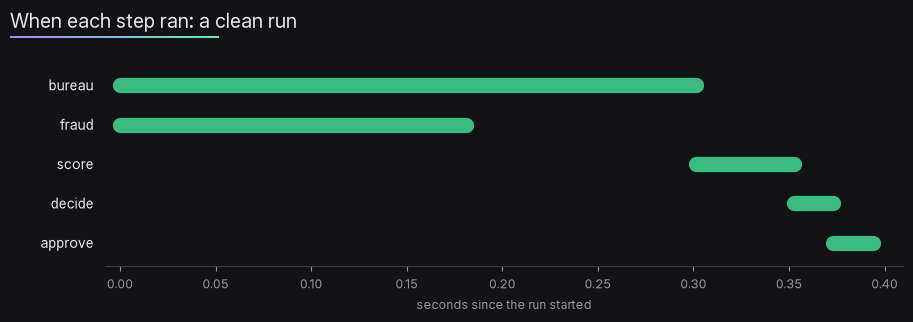

In [6]:
timeline(attempts, order, "When each step ran: a clean run");

## A retry and the other route

This applicant's bureau lookup times out on its first attempt, and their device risk is high. supie waits for the step's backoff and tries `bureau` again, which succeeds. The fraud flag sends the run to `review`, so `approve` is skipped.

In [7]:
second = await run(
    {"id": 2, "bureau_score": 655, "device_risk": 0.93, "flaky_bureau": True}
)
second.output

{'review': {'decision': 'refer'}}

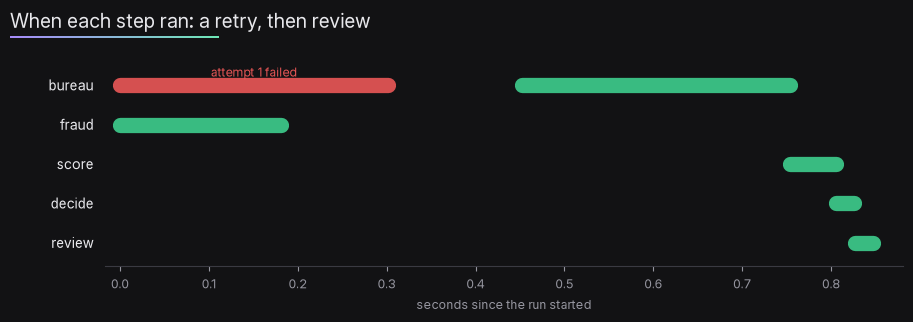

In [8]:
timeline(attempts, order, "When each step ran: a retry, then review");

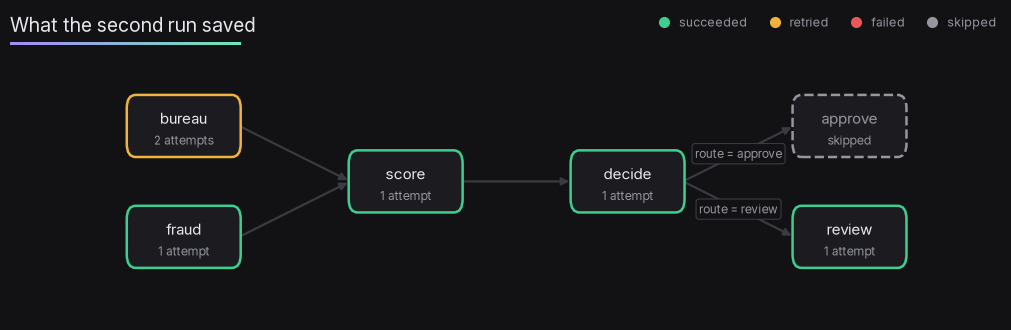

In [9]:
rows = store.runs[second.run_id]["step_rows"]
dag(scoring, rows, "What the second run saved");

## The saved checkpoints

Each finished step is saved with its status, output and attempt count. With the Supabase store, these are rows in `supie_flow_steps`; a run that stops part way resumes from them with `scoring.run(None, run_id=...)`, skipping the steps already saved.

In [10]:
def checkpoints(rows: dict[str, dict[str, Any]]) -> Markdown:
    lines = ["| step | status | attempts | output |", "|---|---|---|---|"]
    for name, row in rows.items():
        lines.append(
            f"| {name} | {row['status']} | {row['attempts']} | `{row['output']}` |"
        )
    return Markdown("\n".join(lines))


checkpoints(rows)

| step | status | attempts | output |
|---|---|---|---|
| fraud | succeeded | 1 | `{'flag': True}` |
| bureau | succeeded | 2 | `{'score': 655}` |
| score | succeeded | 1 | `{'pd': 0.202, 'fraud': True}` |
| decide | succeeded | 1 | `{'route': 'review'}` |
| approve | skipped | 0 | `None` |
| review | succeeded | 1 | `{'decision': 'refer'}` |